<div style="padding:17px 20px;background:#19194b;color:white;border-radius:12px;">
  <div style="font-size:13px;letter-spacing:2px;color:#D8D2FA;">LAB365 · SENAI &nbsp; | &nbsp; SEMANA 02 · AULA 02</div>
  <div style="font-size:28px;font-weight:750;margin:9px 0 5px;">Laboratórios: evidências, ruído e conflitos</div>
  <div style="font-size:16px;color:#DEE4F6;">Dois experimentos · 40 minutos · quatro chamadas distintas ao LLM</div>
</div>

**Sua missão:** executar os testes, ler as respostas reais e descobrir se adicionar documentos prejudica, melhora ou apenas encarece a resposta. Você **não precisa programar**.

**Pergunta fixa:** *“Comprei um curso há 9 dias e tive problemas de acesso. Ainda posso solicitar reembolso?”*

> O cenário é fictício, criado para fins didáticos. Não representa orientação jurídica ou política real de um fornecedor.

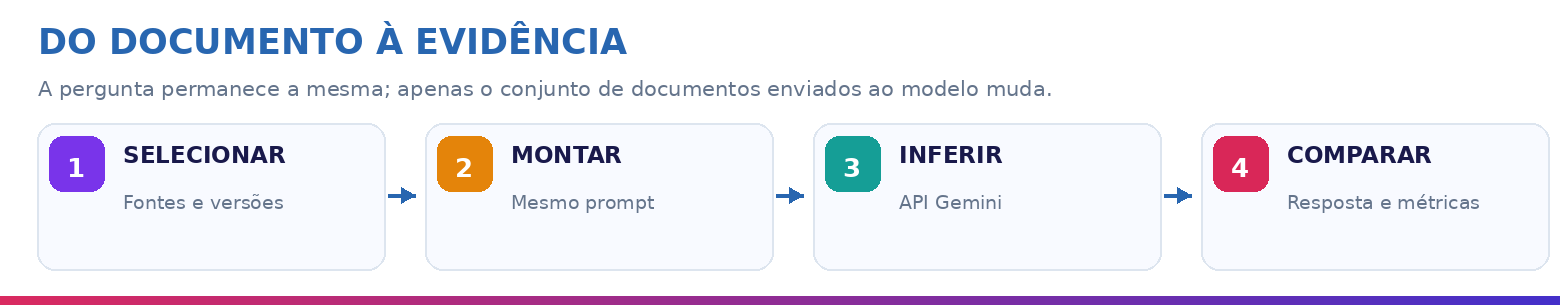

### Preparação — somente uma vez

1. No VS Code, selecione o kernel Python do seu `.venv`.
2. Execute a célula de instalação abaixo.
3. Crie um `.env` **na pasta do notebook**, com:

   ```env
   GEMINI_API_KEY=sua_chave_aqui
   GEMINI_MODEL=gemini-3.5-flash-lite
   ```

4. Na célula seguinte, altere **`EXECUTAR_API = True`**. Depois, execute as células em ordem.

<small>As chamadas usam a API Gemini. Podem consumir cota/créditos; os resultados são salvos para evitar chamadas repetidas. Não compartilhe seu `.env`.</small>

In [ ]:
%pip -q install openai python-dotenv pandas matplotlib

In [1]:
from pathlib import Path
import os
from dotenv import load_dotenv

load_dotenv(Path.cwd() / ".env")
MODELO = os.getenv("GEMINI_MODEL", "gemini-3.5-flash-lite")
EXECUTAR_API = True      # Altere para True para executar as inferências reais
PAUSA_SEGUNDOS = 12      # Intervalo entre requisições novas

print(f"Modelo: {MODELO} | Chave presente: {bool(os.getenv('GEMINI_API_KEY'))} | API habilitada: {EXECUTAR_API}")

Modelo: gemini-3.5-flash-lite | Chave presente: True | API habilitada: True


### Documentos do caso

Os sete documentos abaixo simulam uma base de conhecimento de uma plataforma de cursos. **Leia principalmente os identificadores, a vigência e a exceção de prazo.** Clique em um documento para consultar o texto completo.

In [2]:
import json, re, time, hashlib, html
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

PASTA = Path("resultados_lab_aula02")
PASTA.mkdir(exist_ok=True)
PERGUNTA = "Comprei um curso há 9 dias e tive problemas de acesso. Ainda posso solicitar reembolso?"
DOCUMENTOS = {
    "D1": {"titulo": "Política geral de reembolso", "situacao": "VIGENTE", "texto": "A regra geral para compras de cursos digitais permite solicitar reembolso em até 7 dias corridos após a confirmação da compra. Quando existir uma política de exceção aplicável, essa exceção deve ser considerada junto da regra geral. Uma solicitação não implica aprovação automática."},
    "D2": {"titulo": "Catálogo de cursos", "situacao": "VIGENTE", "texto": "Os cursos disponíveis incluem Python, SQL, desenvolvimento web e segurança. As matrículas podem ocorrer por turmas com datas de início distintas. A organização dos módulos depende da modalidade de cada formação."},
    "D3": {"titulo": "Emissão de certificados", "situacao": "VIGENTE", "texto": "Certificados são emitidos após conclusão do conteúdo e cumprimento dos critérios de participação. O aluno pode acessar o certificado na área de documentos do portal."},
    "D4": {"titulo": "Exceção vigente por falha de acesso", "situacao": "VIGENTE · PRODUÇÃO", "texto": "Para problemas comprovados de acesso que impeçam o uso do curso, o aluno pode solicitar reembolso em até 15 dias corridos contados da compra, mesmo quando ultrapassados os 7 dias da regra geral. A solicitação deve conter evidências da falha, como protocolo de suporte, data da ocorrência ou registro técnico. A aprovação depende da validação dessas evidências."},
    "D5": {"titulo": "Preços e modalidades", "situacao": "VIGENTE", "texto": "Existem cursos avulsos, trilhas e pacotes por assinatura. Preços podem variar por carga horária, condições promocionais e modalidade de acesso. Os valores apresentados no catálogo são atualizados periodicamente."},
    "D6": {"titulo": "Cópia da regra geral (duplicada)", "situacao": "CÓPIA DE D1", "texto": "A regra geral para compras de cursos digitais permite solicitar reembolso em até 7 dias corridos após a confirmação da compra. Quando existir uma política de exceção aplicável, essa exceção deve ser considerada junto da regra geral. Uma solicitação não implica aprovação automática."},
    "D7": {"titulo": "Política anterior sobre acesso", "situacao": "REVOGADO · VERSÃO ANTIGA", "texto": "VERSÃO HISTÓRICA REVOGADA: o prazo máximo de solicitação de reembolso era de 7 dias, inclusive quando ocorriam problemas de acesso. Esta política foi substituída pela versão vigente descrita em D4 e não se aplica a novas solicitações."},
}

for id_, d in DOCUMENTOS.items():
    cor = "#D92758" if "REVOGADO" in d["situacao"] else "#159E96" if id_ in ("D1","D4") else "#E4840A"
    conteudo=html.escape(d['texto'])
    display(HTML(f'<details style="border:1px solid #DEE5EE;border-left:5px solid {cor};padding:9px 14px;margin:5px 0;border-radius:8px"><summary><b>{id_} · {html.escape(d["titulo"])}</b> <span style="color:#64748b">[{html.escape(d["situacao"])}]</span></summary><p style="line-height:1.5;margin:8px 0 2px">{conteudo}</p></details>'))

INSTRUCAO = ("Você é um assistente de atendimento que responde SOMENTE com base nos documentos fornecidos. "
             "Identifique documentos revogados e priorize as políticas vigentes para a situação apresentada. "
             "Explique a conclusão em até quatro frases, cite os IDs das fontes no formato [D1] e [D4], "
             "diferencie a possibilidade de solicitar reembolso de sua aprovação automática. "
             "Se a documentação não sustentar uma conclusão, explicite a incerteza. Não invente regras.")
CENARIOS = {
 "L1_T1": {"nome":"Lab 1 · Contexto completo", "ids":["D1","D2","D3","D4","D5","D6"]},
 "BASE": {"nome":"Lab 1 T2 / Lab 2 A · Selecionado (baseline)", "ids":["D1","D4"]},
 "RUIDO": {"nome":"Lab 2 B · Com ruído", "ids":["D1","D4","D2","D3","D5"]},
 "CONFLITO": {"nome":"Lab 2 C · Com versão revogada", "ids":["D1","D4","D7"]},
}

def contexto(ids):
    return "\n\n".join(f"[{i}] {DOCUMENTOS[i]['titulo']} | STATUS: {DOCUMENTOS[i]['situacao']}\n{DOCUMENTOS[i]['texto']}" for i in ids)

def prompt(ids):
    return "DOCUMENTOS:\n" + contexto(ids) + "\n\nPERGUNTA DO USUÁRIO:\n" + PERGUNTA

def resultado_arquivo(codigo):
    p = json.dumps({"modelo":MODELO,"instrucao":INSTRUCAO,"pergunta":PERGUNTA,"docs":contexto(CENARIOS[codigo]["ids"])}, ensure_ascii=False)
    chave = hashlib.sha256(p.encode()).hexdigest()[:14]
    return PASTA / f"{codigo.lower()}_{chave}.json"

def executar(codigo):
    c = CENARIOS[codigo]; arq = resultado_arquivo(codigo)
    if arq.exists():
        d = json.loads(arq.read_text(encoding="utf-8"))

        saida = d.get("resposta", "")
        d["citacoes"] = ", ".join(
            f"[{id_}]"
            for id_ in sorted(set(re.findall(r"\bD[1-7]\b", saida)))
        )

        arq.write_text(
            json.dumps(d, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )

        d["origem"] = "checkpoint"
        return d
    if not EXECUTAR_API:
        return {"codigo":codigo,"status":"não executado","nome":c["nome"],"fontes":", ".join(c["ids"]),"resposta":"Ative EXECUTAR_API = True e rode novamente.","origem":"prévia"}
    chave=os.getenv("GEMINI_API_KEY")
    if not chave:
        return {"codigo":codigo,"status":"sem chave","nome":c["nome"],"fontes":", ".join(c["ids"]),"resposta":"Configure GEMINI_API_KEY no .env.","origem":"prévia"}
    try:
        from openai import OpenAI
        client = OpenAI(api_key=chave, base_url="https://generativelanguage.googleapis.com/v1beta/openai/", max_retries=1, timeout=90)
        inicio=time.perf_counter()
        resp=client.chat.completions.create(model=MODELO, messages=[{"role":"system","content":INSTRUCAO},{"role":"user","content":prompt(c['ids'])}], max_tokens=1200)
        duracao=round(time.perf_counter()-inicio,3)
        saida=resp.choices[0].message.content or ""
        u=resp.usage
        d={"codigo":codigo,"nome":c["nome"],"status":"ok","modelo":MODELO,"fontes":", ".join(c['ids']),"resposta":saida,"citacoes": ", ".join(f"[{id_}]"for id_ in sorted(set(re.findall(r"\bD[1-7]\b", saida)))),"tokens_entrada":getattr(u,"prompt_tokens",None),"tokens_saida":getattr(u,"completion_tokens",None),"latencia_s":duracao,"origem":"API","executado_em":datetime.now(timezone.utc).isoformat()}
        arq.write_text(json.dumps(d,ensure_ascii=False,indent=2),encoding='utf-8')
        return d
    except Exception as exc:
        return {"codigo":codigo,"nome":c['nome'],"status":"erro API","fontes":", ".join(c['ids']),"resposta":f"{type(exc).__name__}: {str(exc)[:240]}","origem":"API"}

def executar_grupo(codigos):
    registros=[]
    for i,codigo in enumerate(codigos,1):
        print(f"[{i}/{len(codigos)}] {CENARIOS[codigo]['nome']}")
        arq=resultado_arquivo(codigo)
        novo=EXECUTAR_API and bool(os.getenv('GEMINI_API_KEY')) and not arq.exists()
        r=executar(codigo)
        registros.append(r)
        if novo and i<len(codigos):
            time.sleep(PAUSA_SEGUNDOS)
    for r in registros:
        cor = '#D92758' if r['status']=='erro API' else '#159E96' if r['status']=='ok' else '#E4840A'
        display(HTML(f'<div style="border:1px solid #DEE5EE;border-left:5px solid {cor};border-radius:8px;padding:13px;margin:9px 0"><b>{html.escape(r["nome"])}</b> &nbsp; <small>{html.escape(r["status"])} · {html.escape(r["origem"])}</small><p style="margin:7px 0"><b>Documentos:</b> {html.escape(r["fontes"])}</p><p style="line-height:1.55;margin:7px 0">{html.escape(r["resposta"])}</p>{(f"<small>Tokens entrada: {r.get('tokens_entrada')} · saída: {r.get('tokens_saida')} · latência: {r.get('latencia_s')} s</small>" if r["status"]=="ok" else "")}</div>'))
    return registros

## Laboratório 1 — Contexto completo × selecionado

**Hipótese:** remover documentos irrelevantes e duplicados pode reduzir o consumo sem prejudicar a resposta.

- **Teste 1:** envie D1–D6.
- **Teste 2:** envie apenas D1 e D4.

**Execute a próxima célula** e observe: a resposta mudou? Quais evidências foram citadas?

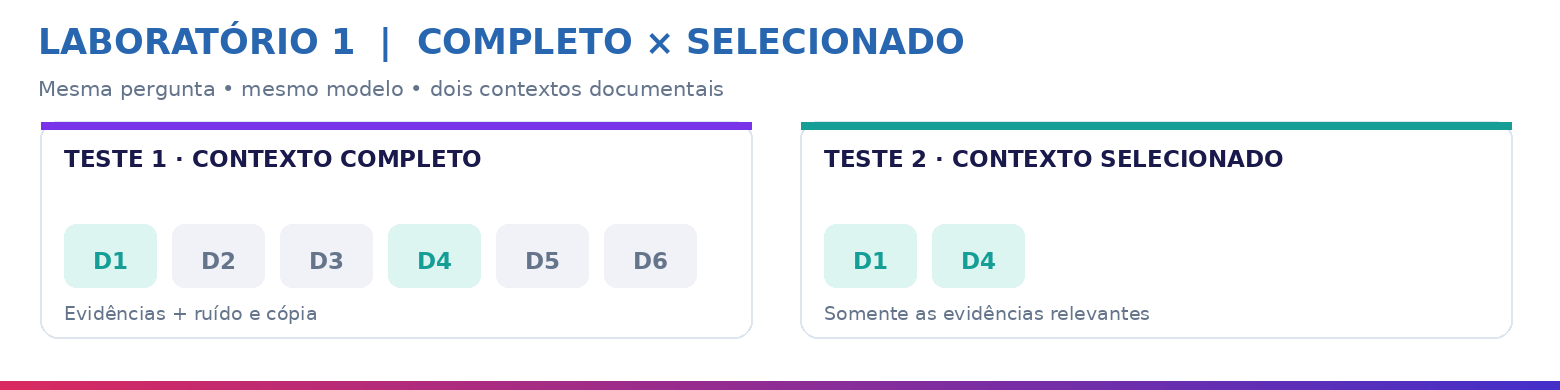

In [3]:
RESULTADO_LAB1 = executar_grupo(["L1_T1", "BASE"])

[1/2] Lab 1 · Contexto completo
[2/2] Lab 1 T2 / Lab 2 A · Selecionado (baseline)


**Anote para discutir:** as duas respostas consideraram a exceção por falha de acesso? Houve economia de tokens? Uma resposta correta é necessariamente a mais longa?

## Laboratório 2 — Ruído × conflito de versões

**Hipótese:** documentos irrelevantes ou uma política antiga podem interferir na utilização das evidências.

- **A — Baseline:** D1 + D4 (reutilizado do laboratório anterior).
- **B — Ruído:** adicione D2, D3 e D5.
- **C — Conflito:** adicione D7, que está marcado como **revogado**.

Execute e investigue se o modelo distingue **informação encontrada** de **política vigente**.

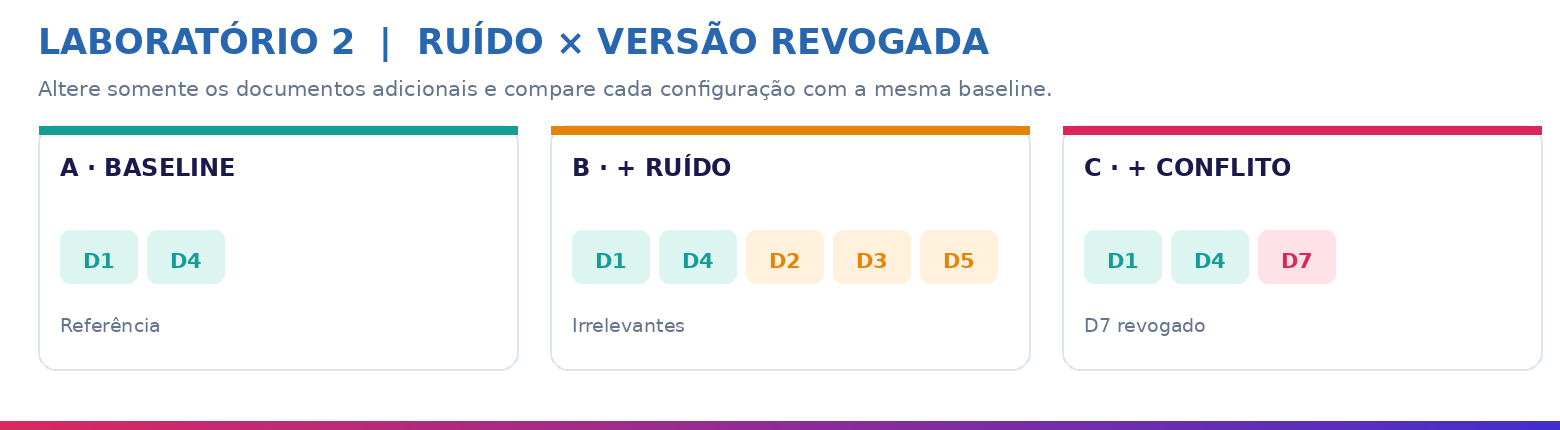

In [4]:
RESULTADO_LAB2 = executar_grupo(["BASE", "RUIDO", "CONFLITO"])

[1/3] Lab 1 T2 / Lab 2 A · Selecionado (baseline)
[2/3] Lab 2 B · Com ruído
[3/3] Lab 2 C · Com versão revogada


## Compare as quatro execuções

A tabela abaixo reúne respostas, fontes, tokens e latência. Ela é salva em CSV para você registrar sua avaliação. **A resposta do modelo não é corrigida automaticamente:** sua tarefa é verificar se ela está sustentada nas fontes.

,Cenário,Documentos,Status,Tokens entrada,Tokens saída,Latência (s),Fontes citadas,Correção (0-2),Fundamentação (0-2)
0,Lab 1 · Contexto completo,"D1, D2, D3, D4, D5, D6",ok,550,94,18.420,"[D1], [D4]",,
1,Lab 1 T2 / Lab 2 A · Selecionado (baseline),"D1, D4",ok,307,96,15.958,"[D1], [D4]",,
2,Lab 2 B · Com ruído,"D1, D4, D2, D3, D5",ok,468,116,14.235,"[D1], [D4]",,
3,Lab 2 C · Com versão revogada,"D1, D4, D7",ok,382,125,14.238,"[D1], [D4], [D7]",,



Planilha para avaliação: /home/wanderson/Documentos/AULAS/SENAI/IA APLICADA À PRODUTIVIDADE NO DESENVOLVIMENTO/Semana 02/dia 2/resultados_lab_aula02/comparacao_laboratorios_aula02.csv


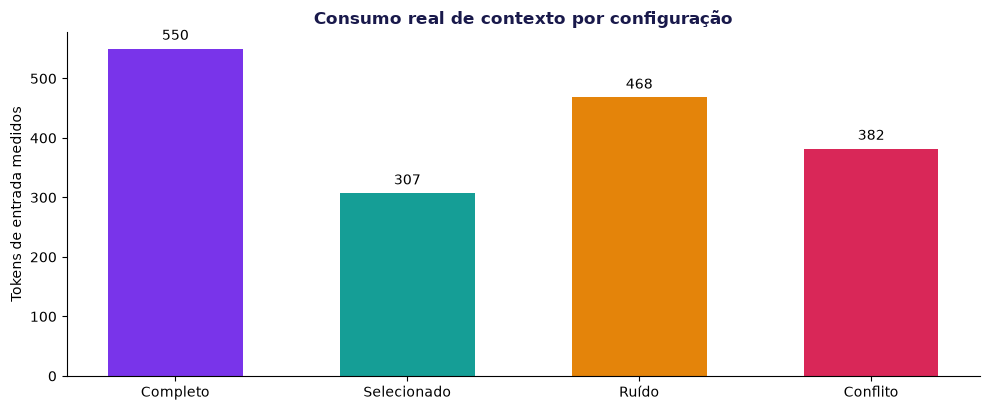

Economia de entrada ao selecionar D1 + D4: 44.2% (uma execução por cenário).


In [5]:
# Carregar apenas os resultados realmente executados e salvos.
linhas=[]
for codigo,c in CENARIOS.items():
    arq=resultado_arquivo(codigo)
    if arq.exists():
        r=json.loads(arq.read_text(encoding="utf-8"))
        linhas.append({"Cenário":c["nome"],"Documentos":r["fontes"],"Status":r["status"],
                       "Tokens entrada":r.get("tokens_entrada"),"Tokens saída":r.get("tokens_saida"),
                       "Latência (s)":r.get("latencia_s"),"Fontes citadas":r.get("citacoes",""),
                       "Resposta":r["resposta"],"Correção (0-2)":"","Fundamentação (0-2)":"","Observações":""})
if linhas:
    tabela=pd.DataFrame(linhas)
    destino=PASTA/"comparacao_laboratorios_aula02.csv"
    tabela.to_csv(destino,index=False,encoding="utf-8-sig")
    display(tabela.drop(columns=["Resposta","Observações"]))
    print(f"\nPlanilha para avaliação: {destino.resolve()}")
    if len(tabela)>=2:
        df_plot=tabela.dropna(subset=["Tokens entrada"])
        if not df_plot.empty:
            fig,ax=plt.subplots(figsize=(10,4.2))
            cores=["#7934EA","#159E96","#E4840A","#D92758"][:len(df_plot)]
            barras=ax.bar(range(len(df_plot)),df_plot["Tokens entrada"],color=cores,width=.58)
            rotulos=[("Completo" if "Contexto completo" in nome else "Selecionado" if "Selecionado" in nome else "Ruído" if "ruído" in nome else "Conflito") for nome in df_plot["Cenário"]]
            ax.set_xticks(range(len(df_plot)),rotulos)
            ax.set_ylabel("Tokens de entrada medidos")
            ax.set_title("Consumo real de contexto por configuração",fontweight="bold",color="#19194B")
            ax.bar_label(barras,padding=4)
            ax.spines[['top','right']].set_visible(False)
            plt.tight_layout();plt.show()
    if "Lab 1 · Contexto completo" in set(tabela["Cenário"]) and "Lab 1 T2 / Lab 2 A · Selecionado (baseline)" in set(tabela["Cenário"]):
        a=float(tabela.loc[tabela["Cenário"]=="Lab 1 · Contexto completo","Tokens entrada"].iloc[0])
        b=float(tabela.loc[tabela["Cenário"]=="Lab 1 T2 / Lab 2 A · Selecionado (baseline)","Tokens entrada"].iloc[0])
        print(f"Economia de entrada ao selecionar D1 + D4: {(1-b/a)*100:.1f}% (uma execução por cenário)." if a else "")
else:
    print("Sem chamadas reais concluídas. Configure o .env, ative EXECUTAR_API e execute os laboratórios.")

### Critério de avaliação (preencha no CSV)

| Nota | **Correção da resposta** | **Fundamentação** |
|---|---|---|
| **2** | Aplica corretamente a política ao caso e menciona as condições. | Cita a(s) fonte(s) vigente(s) que sustentam as afirmações. |
| **1** | Parcial: conclusão plausível, mas omite condição importante. | Fonte incompleta ou argumento pouco rastreável. |
| **0** | Contradiz a política vigente ou inventa regra. | Cita documento inadequado como vigente ou não sustenta a conclusão. |

<details><summary><b>Conferir a resposta de referência após os testes</b></summary>
<p>A regra geral é de <b>7 dias (D1)</b>, mas a política vigente prevê <b>até 15 dias para falha comprovada de acesso (D4)</b>. Uma compra feita há 9 dias ainda pode solicitar reembolso <b>se houver evidência da falha</b>; isso não garante aprovação automática. <b>D7 é revogado</b> e não deve prevalecer.</p></details>

### Entrega (5 minutos)

Responda brevemente no CSV ou em texto: **(1)** a seleção manteve a qualidade? **(2)** quanto variaram tokens e latência? **(3)** ruído ou revogação provocaram erro? **(4)** qual configuração você usaria e por quê?

> Se todos os testes estiverem corretos, esse também é um resultado válido: analise a economia de contexto. Uma falha não precisa ocorrer para que o experimento tenha valor. **A latência de uma única chamada não comprova qual estratégia é mais rápida.**